SyntaxError: invalid syntax (147348282.py, line 1)

In [11]:
pip install opencv-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


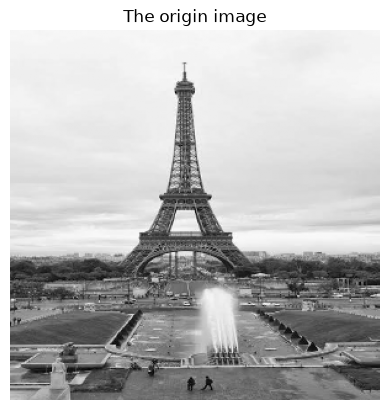

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


img = cv2.imread("borj.jpg" , cv2.IMREAD_GRAYSCALE)

plt.title("The origin image")
img = cv2.resize(img,(300,300))
plt.imshow(img,cmap="gray")
plt.axis('off')
plt.show()


Convolutional Approach

[[-1 -1 -1]
 [-1  8 -1]
 [-1 -1 -1]]
(3, 3)
the image with -1 depth : 


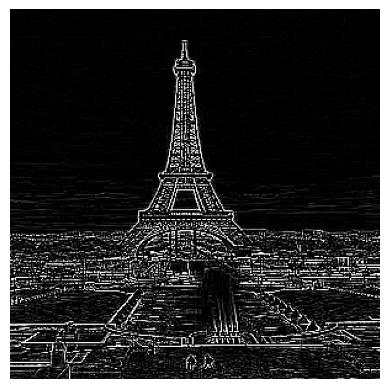

the image with 0 depth : 


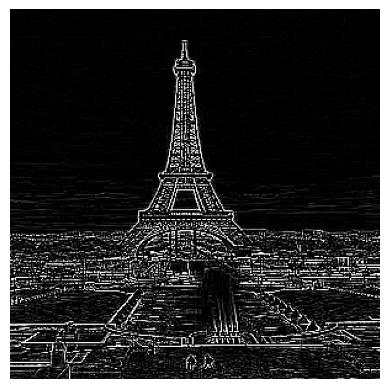

In [39]:
import numpy as np
import cv2
kernel = np.array([
     [-1,-1,-1],
    [-1, 8,-1],
    [-1,-1,-1]
])

print(kernel)
print(kernel.shape)

edges = cv2.filter2D(img,-1,kernel)
print("the image with -1 depth : ")
plt.imshow(edges,cmap='gray')

plt.axis('off')
plt.show()

print("the image with 0 depth : ")
edges2 = cv2.filter2D(img,0,kernel)

plt.imshow(edges2,cmap='gray')
plt.axis('off')
plt.show()



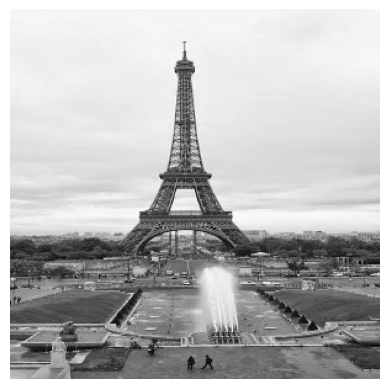

In [42]:
kernel = np.ones((3,3))/9

blur = cv2.filter2D(img, -1, kernel)
plt.imshow(img , cmap='gray')
plt.axis('off')
plt.show()

Point Detection

In [45]:
kernel = np.array([
    [-1,-1 ,-1],
    [-1,8 ,-1],
    [-1,-1 ,-1]
])
#Detect isolated bright pixels.
points = cv2.filter2D(img, -1, kernel)
print(points)
# Central pixel differs strongly from neighbors.

# Detector responds strongly.

[[ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 ...
 [ 0  0  0 ... 19  0  0]
 [12 32 34 ...  0  0  0]
 [ 0 59 31 ... 66 78 86]]


3. Line Detection

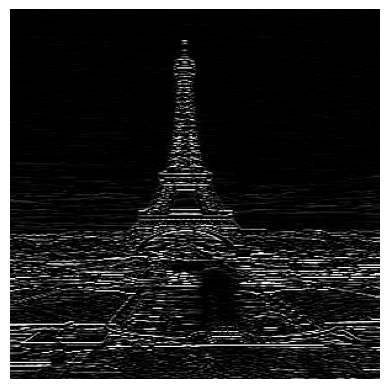

In [52]:
kernel_horizontal = np.array([
    [-1,-1,-1],
    [ 2, 2, 2],
    [-1,-1,-1]
])
horizontal_lines = cv2.filter2D(img,-1,kernel_horizontal)
plt.imshow(horizontal_lines , cmap='gray')
plt.axis('off')
plt.show()

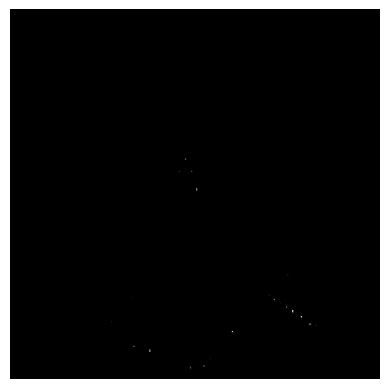

In [53]:
kernel_vertical = np.array([
    [-1,2,-1],
    [ -1,2,-1],
    [-1,-2,-1]
])
vertical_lines = cv2.filter2D(img,-1,  kernel_vertical)
plt.imshow(vertical_lines , cmap='gray')
plt.axis('off')
plt.show()

Roberts Operator

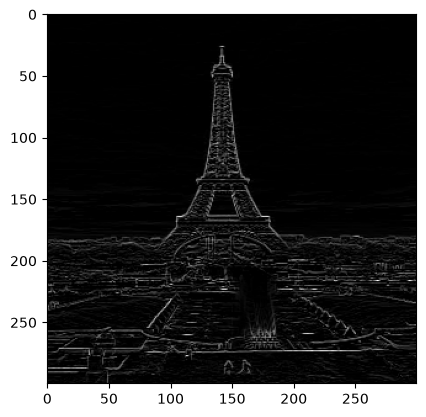

In [54]:
robert_x = np.array([
    [1,0],
    [0,-1]
])
robert_y = np.array([
    [0,1],
    [-1,0]
])
gx=cv2.filter2D(img,-1,robert_x)
gy=cv2.filter2D(img,-1,robert_y)

roberts = cv2.magnitude(
    gx.astype("float32"),
    gy.astype("float32")
)
plt.imshow(roberts,cmap='gray')

